# VETRA v3.0 – Side View Keypoint Model Training (YOLO-format labels)

 This notebook trains a simple keypoint regression model for side-view images.
 Assumptions:
 - Dataset structure:
     dataset/
       images/
         train/   <-- .jpg/.png side view images
         val/
       labels/
         train/   <-- .txt YOLO keypoint labels (same basename as images)
         val/
 - Label format (one object per image):
     class x_center y_center w h kx1 ky1 kx2 ky2 ... kxN kyN
   All coords normalized in [0,1].

 The model:
 - Backbone: ResNet18
 - Head: fully connected layer outputting 2*N keypoints (normalized)
 - Loss: MSE between predicted and target normalized keypoints

 GPU is used if available (torch.cuda.is_available()).


#  1. Imports & Basic Setup

In [3]:
import os
from pathlib import Path
import shutil
import random

from ultralytics import YOLO
import torch

In [4]:
print("🔥 CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Using GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ No GPU found, training will fall back to CPU.")

🔥 CUDA available: True
Using GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [5]:
# ====== PATH CONFIG ======
# Folder where your ORIGINAL side-view images and labels are
RAW_IMAGES_DIR = Path(r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\left_side_view_jpg_images")   # e.g. "/content/side/images"
RAW_LABELS_DIR = Path(r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\left_side_view_yolo_labels")   # e.g. "/content/side/labels"

# Where to create the YOLO-formatted dataset
VIEW_TYPE = "side"  # just a tag for naming
DATASET_ROOT = Path(f"./vetra_{VIEW_TYPE}_pose_dataset").resolve()

IMAGES_TRAIN_DIR = DATASET_ROOT / "images" / "train"
IMAGES_VAL_DIR   = DATASET_ROOT / "images" / "val"
LABELS_TRAIN_DIR = DATASET_ROOT / "labels" / "train"
LABELS_VAL_DIR   = DATASET_ROOT / "labels" / "val"

for d in [IMAGES_TRAIN_DIR, IMAGES_VAL_DIR, LABELS_TRAIN_DIR, LABELS_VAL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Dataset root will be:", DATASET_ROOT)


Dataset root will be: D:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_side_pose_dataset


In [6]:
# ====== KEYPOINT & TRAINING CONFIG ======

# Number of keypoints in YOUR side-view labels
NUM_KEYPOINTS = 14   # <-- change if you used a different number

# How many copies per image (you asked for 4 copies)
COPY_FACTOR = 4

# Train/val split
TRAIN_RATIO = 0.8
RANDOM_SEED = 42

# YOLO model + training hyperparams
CONFIG = {
    # You can also use "yolov8s-pose.pt" or "yolo11n-pose.pt" if you installed YOLO11
    "base_model": "yolov8n-pose.pt",
    "epochs": 100,
    "imgsz": 640,
    "batch_size": 16,
    "patience": 20
}

print("CONFIG =", CONFIG)


CONFIG = {'base_model': 'yolov8n-pose.pt', 'epochs': 100, 'imgsz': 640, 'batch_size': 16, 'patience': 20}


In [7]:
# Try to inspect one label file to infer keypoint dimensions
example_labels = list(RAW_LABELS_DIR.glob("*.txt"))
if not example_labels:
    raise RuntimeError(f"No .txt labels found in {RAW_LABELS_DIR}")

example_path = example_labels[0]
print("Example label file:", example_path)

with open(example_path, "r") as f:
    line = f.readline().strip()

parts = line.split()
cls_id = parts[0]
bbox = list(map(float, parts[1:5]))
kpt_vals = list(map(float, parts[5:]))

print(f"Class ID: {cls_id}")
print(f"BBox (cx, cy, w, h): {bbox}")
print(f"Number of keypoint values: {len(kpt_vals)}")

if len(kpt_vals) % 2 == 0:
    kpt_dim = 2
elif len(kpt_vals) % 3 == 0:
    kpt_dim = 3
else:
    raise ValueError("Keypoint values do not match 2D or 3D format (xy or xyv).")

num_kpts_detected = len(kpt_vals) // kpt_dim
print(f"Detected {num_kpts_detected} keypoints with dimension {kpt_dim}.")

if num_kpts_detected != NUM_KEYPOINTS:
    print("⚠️ WARNING: NUM_KEYPOINTS does not match labels. Update NUM_KEYPOINTS.")


Example label file: D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\left_side_view_yolo_labels\1.txt
Class ID: 0
BBox (cx, cy, w, h): [0.46564980158730157, 0.5347222222222222, 0.9312996031746031, 0.8267195767195767]
Number of keypoint values: 28
Detected 14 keypoints with dimension 2.


In [8]:
# Supported image extensions
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# Gather base samples
base_samples = []
for img_path in sorted(RAW_IMAGES_DIR.iterdir()):
    if img_path.suffix.lower() not in IMG_EXTS:
        continue
    label_path = RAW_LABELS_DIR / (img_path.stem + ".txt")
    if not label_path.exists():
        print(f"⚠️ No label for image {img_path.name}, skipping.")
        continue
    base_samples.append((img_path, label_path))

print(f"Found {len(base_samples)} base samples with labels.")

# Create COPY_FACTOR copies with new stems
all_samples = []
for img_path, lbl_path in base_samples:
    for i in range(COPY_FACTOR):
        # e.g. cow_001 -> cow_001_c0, cow_001_c1, ...
        new_stem = f"{img_path.stem}_c{i}"
        all_samples.append((img_path, lbl_path, new_stem))

print(f"Total samples after duplication: {len(all_samples)}")

# Shuffle and split
random.seed(RANDOM_SEED)
random.shuffle(all_samples)

split_idx = int(len(all_samples) * TRAIN_RATIO)
train_samples = all_samples[:split_idx]
val_samples   = all_samples[split_idx:]

print(f"Train samples: {len(train_samples)}")
print(f"Val samples:   {len(val_samples)}")


⚠️ No label for image 79.jpg, skipping.
Found 126 base samples with labels.
Total samples after duplication: 504
Train samples: 403
Val samples:   101


In [9]:
# Function to copy image + label with new names into destination
def copy_sample(img_src: Path, lbl_src: Path, new_stem: str, split: str):
    if split == "train":
        img_dst_dir = IMAGES_TRAIN_DIR
        lbl_dst_dir = LABELS_TRAIN_DIR
    else:
        img_dst_dir = IMAGES_VAL_DIR
        lbl_dst_dir = LABELS_VAL_DIR
    
    img_dst = img_dst_dir / f"{new_stem}{img_src.suffix.lower()}"
    lbl_dst = lbl_dst_dir / f"{new_stem}.txt"
    
    shutil.copy2(img_src, img_dst)
    shutil.copy2(lbl_src, lbl_dst)

# Copy all
for img_path, lbl_path, new_stem in train_samples:
    copy_sample(img_path, lbl_path, new_stem, "train")

for img_path, lbl_path, new_stem in val_samples:
    copy_sample(img_path, lbl_path, new_stem, "val")

print("✅ Dataset duplicated and split.")
print("Train images:", len(list(IMAGES_TRAIN_DIR.glob('*'))))
print("Val   images:", len(list(IMAGES_VAL_DIR.glob('*'))))


✅ Dataset duplicated and split.
Train images: 403
Val   images: 101


In [10]:
dataset_yaml_path = DATASET_ROOT / f"vetra_{VIEW_TYPE}_pose.yaml"

yaml_text = f"""# VETRA {VIEW_TYPE} pose dataset
path: {DATASET_ROOT.as_posix()}
train: images/train
val: images/val

kpt_shape: [{NUM_KEYPOINTS}, 2]

names:
  0: side_view
"""

dataset_yaml_path.write_text(yaml_text)
print("📄 Dataset YAML created at:", dataset_yaml_path)
print("----- YAML CONTENT -----")
print(dataset_yaml_path.read_text())


📄 Dataset YAML created at: D:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_side_pose_dataset\vetra_side_pose.yaml
----- YAML CONTENT -----
# VETRA side pose dataset
path: D:/Projects/VETRA/Codes/VETRA v3.0/Training and Processing/vetra_side_pose_dataset
train: images/train
val: images/val

kpt_shape: [14, 2]

names:
  0: side_view



In [11]:
def train_yolo_model(view_type: str, yaml_file: Path, num_keypoints: int):
    """Train YOLO pose estimation model for a specific view."""
    print(f"\n🚀 Training YOLO Pose Model for {view_type.upper()} VIEW")
    print("=" * 60)
    
    project_name = f"runs/{view_type}_view"
    model_run_name = f"yolo_pose_{view_type}_v1"
    
    print("📊 Training Details:")
    print(f"   Base model:   {CONFIG['base_model']}")
    print(f"   Epochs:       {CONFIG['epochs']}")
    print(f"   Image size:   {CONFIG['imgsz']}")
    print(f"   Batch size:   {CONFIG['batch_size']}")
    print(f"   Keypoints:    {num_keypoints}")
    print(f"   Project dir:  {project_name}")
    print(f"   Run name:     {model_run_name}")
    print(f"   Dataset yaml: {yaml_file}")
    
    device = "0" if torch.cuda.is_available() else "cpu"
    print(f"   Device:       {device}")
    
    # Load pretrained pose model
    model = YOLO(CONFIG["base_model"])
    
    # Train
    results = model.train(
        data=str(yaml_file),
        epochs=CONFIG["epochs"],
        imgsz=CONFIG["imgsz"],
        batch=CONFIG["batch_size"],
        project=project_name,
        name=model_run_name,
        patience=CONFIG["patience"],
        save=True,
        exist_ok=True,
        verbose=True,
        workers=4,
        device=device
    )
    
    print(f"✅ {view_type.upper()} VIEW training completed!")
    print(f"📁 Results folder: {project_name}/{model_run_name}")
    print("💾 Best weights:", results.save_dir / "weights" / "best.pt")
    
    return model, results


In [12]:
print("🎯 STARTING YOLO POSE TRAINING FOR SIDE VIEW")
print("=" * 60)

side_model, side_results = train_yolo_model(
    view_type=VIEW_TYPE,
    yaml_file=dataset_yaml_path,
    num_keypoints=NUM_KEYPOINTS
)


🎯 STARTING YOLO POSE TRAINING FOR SIDE VIEW

🚀 Training YOLO Pose Model for SIDE VIEW
📊 Training Details:
   Base model:   yolov8n-pose.pt
   Epochs:       100
   Image size:   640
   Batch size:   16
   Keypoints:    14
   Project dir:  runs/side_view
   Run name:     yolo_pose_side_v1
   Dataset yaml: D:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_side_pose_dataset\vetra_side_pose.yaml
   Device:       0
New https://pypi.org/project/ultralytics/8.3.235 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.203  Python-3.11.3 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_side_pose_dataset\vetra_

In [26]:
from ultralytics import YOLO
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
import torch

In [27]:
# 🔧 PATHS – change these to your setup
MODEL_PATH = r"D:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\runs\side_view\yolo_pose_side_v1\weights\best.pt"

# Folder with images you want to visualize
# You can point this to your val or train images folder
IMAGES_DIR = Path(r"vetra_side_pose_dataset\images\val")

# Load model
device = "0" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

model = YOLO(MODEL_PATH)


Using device: 0


In [28]:
# SIDE VIEW KEYPOINTS (14) – order must match your labels
KEYPOINT_NAMES = [
    "hoof_rear_left",          # 0
    "hoof_toe_tip_left",       # 1
    "hoof_heel_hairline_left", # 2
    "hock_left",               # 3
    "stifle_left",             # 4
    "hook_left",               # 5
    "pin_left",                # 6
    "spine_mid_hips",          # 7
    "spine_last_rib_top",      # 8
    "barrel_last_rib_bottom",  # 9
    "shoulder_point",          # 10
    "elbow_point",             # 11
    "loin_midpoint",           # 12
    "udder_floor_centre_rear"  # 13
]

name_to_idx = {n: i for i, n in enumerate(KEYPOINT_NAMES)}
name_to_idx


{'hoof_rear_left': 0,
 'hoof_toe_tip_left': 1,
 'hoof_heel_hairline_left': 2,
 'hock_left': 3,
 'stifle_left': 4,
 'hook_left': 5,
 'pin_left': 6,
 'spine_mid_hips': 7,
 'spine_last_rib_top': 8,
 'barrel_last_rib_bottom': 9,
 'shoulder_point': 10,
 'elbow_point': 11,
 'loin_midpoint': 12,
 'udder_floor_centre_rear': 13}

In [29]:
SKELETON_EDGES = [
    # Hind hoof + foot
    (name_to_idx["hoof_rear_left"], name_to_idx["hock_left"]),           # 0–3
    (name_to_idx["hoof_rear_left"], name_to_idx["hoof_toe_tip_left"]),   # 0–1
    (name_to_idx["hoof_rear_left"], name_to_idx["hoof_heel_hairline_left"]),  # 0–2

    # Hind leg to rump
    (name_to_idx["hock_left"], name_to_idx["stifle_left"]),              # 3–4
    (name_to_idx["stifle_left"], name_to_idx["pin_left"]),               # 4–6
    (name_to_idx["pin_left"], name_to_idx["hook_left"]),                 # 6–5
    (name_to_idx["hook_left"], name_to_idx["spine_mid_hips"]),           # 5–7

    # Topline
    (name_to_idx["spine_mid_hips"], name_to_idx["loin_midpoint"]),       # 7–12
    (name_to_idx["loin_midpoint"], name_to_idx["spine_last_rib_top"]),   # 12–8
    (name_to_idx["spine_last_rib_top"], name_to_idx["shoulder_point"]),  # 8–10

    # Body depth (NDDB body depth line)
    (name_to_idx["spine_last_rib_top"], name_to_idx["barrel_last_rib_bottom"]),  # 8–9

    # Udder depth path
    (name_to_idx["barrel_last_rib_bottom"], name_to_idx["udder_floor_centre_rear"]),  # 9–13
    (name_to_idx["hock_left"], name_to_idx["udder_floor_centre_rear"]),              # 3–13

    # Shoulder / heart-girth line (approx
    (name_to_idx["shoulder_point"], name_to_idx["elbow_point"]),         # 10–11
    (name_to_idx["spine_last_rib_top"], name_to_idx["elbow_point"]),     # 8–11  <-- heart-girth cross-section

    # Body length (NDDB body length line)
    (name_to_idx["shoulder_point"], name_to_idx["pin_left"]),            # 10–6
]


In [30]:
TRAIT_CONNECTIONS = {
    # === Dairy strength ===
    # Stature: top of spine between hips to ground (use rear hoof ground point)
    "stature": [
        ("spine_mid_hips", "hoof_rear_left"),          # 7–0
    ],

    # Heart girth (approx. from side view):
    # use vertical-ish distance between back near last rib and elbow
    "heart_girth": [
        ("spine_last_rib_top", "elbow_point"),         # 8–11
    ],

    # Body length: point of shoulder to pin bone
    "body_length": [
        ("shoulder_point", "pin_left"),                # 10–6
    ],

    # Body depth: top of spine at last rib to bottom of barrel at last rib
    "body_depth": [
        ("spine_last_rib_top", "barrel_last_rib_bottom"),  # 8–9
    ],

    # Angularity: angle between vertical and the line through last rib
    # (we'll use the same 8–9 line as for body depth)
    "angularity": [
        ("spine_last_rib_top", "barrel_last_rib_bottom"),  # 8–9
    ],

    # === Rump ===
    # Rump angle: hip to pin (single side approximation)
    "rump_angle": [
        ("hook_left", "pin_left"),                     # 5–6
    ],

    # === Feet and legs ===
    # Rear legs set: angle at hock (stifle-hock-hoof)
    "rear_legs_set": [
        ("stifle_left", "hock_left"),                  # upper leg
        ("hock_left", "hoof_rear_left"),               # lower leg
    ],

    # Foot angle: angle at hoof front from floor to hairline
    "foot_angle": [
        ("hoof_toe_tip_left", "hoof_heel_hairline_left"),  # 1–2
    ],

    # === Udder ===
    # Udder depth: udder floor to line through hock / ground
    "udder_depth": [
        ("udder_floor_centre_rear", "hock_left"),      # 13–3
        ("udder_floor_centre_rear", "hoof_rear_left"), # 13–0 (optional second ref)
    ],

    # === General ===
    # Body condition score: shape around loin + hooks + pins
    "body_condition_score": [
        ("loin_midpoint", "hook_left"),                # 12–5
        ("loin_midpoint", "pin_left"),                 # 12–6
    ],
}

TRAIT_EDGES_IDX = {
    trait: [(name_to_idx[a], name_to_idx[b]) for (a, b) in edges]
    for trait, edges in TRAIT_CONNECTIONS.items()
}
TRAIT_EDGES_IDX


{'stature': [(7, 0)],
 'heart_girth': [(8, 11)],
 'body_length': [(10, 6)],
 'body_depth': [(8, 9)],
 'angularity': [(8, 9)],
 'rump_angle': [(5, 6)],
 'rear_legs_set': [(4, 3), (3, 0)],
 'foot_angle': [(1, 2)],
 'udder_depth': [(13, 3), (13, 0)],
 'body_condition_score': [(12, 5), (12, 6)]}

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

def plot_pose_on_image(img_path: Path, model, conf: float = 0.5, figsize=(7, 7)):
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print("Could not read image:", img_path)
        return
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    results = model(str(img_path), conf=conf, verbose=False)
    res = results[0]

    plt.figure(figsize=figsize)
    plt.imshow(img_rgb)
    plt.axis("off")

    if res.keypoints is None or len(res.keypoints) == 0:
        print("No keypoints detected.")
        plt.show()
        return

    kpts = res.keypoints.xy[0].cpu().numpy()  # [num_kpts, 2]

    # Draw skeleton
    for i, j in SKELETON_EDGES:
        x1, y1 = kpts[i]
        x2, y2 = kpts[j]
        if not (np.isnan(x1) or np.isnan(y1) or np.isnan(x2) or np.isnan(y2)):
            plt.plot([x1, x2], [y1, y2], linewidth=2)

    # Draw keypoints with index + name
    for idx, (x, y) in enumerate(kpts):
        if np.isnan(x) or np.isnan(y):
            continue
        plt.scatter(x, y, s=30)
        label = f"{idx}:{KEYPOINT_NAMES[idx]}"
        plt.text(
            x + 3, y - 3, label,
            fontsize=7,
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none')
        )

    plt.title(img_path.name)
    plt.show()


Found 101 images
Sample: vetra_side_pose_dataset\images\val\54_c0.jpg


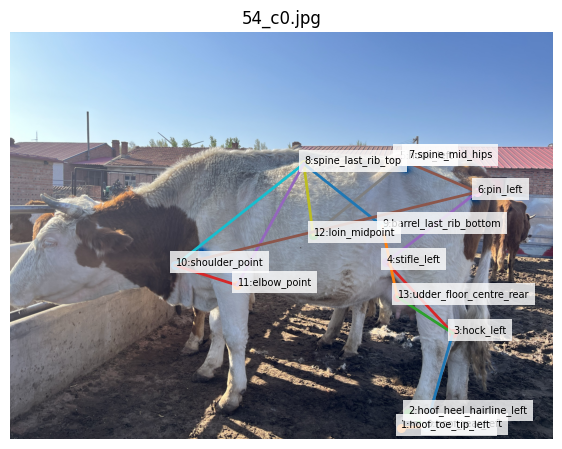

In [32]:
%matplotlib inline
all_images = [p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
print("Found", len(all_images), "images")

sample = random.choice(all_images)
print("Sample:", sample)
plot_pose_on_image(sample, model, conf=0.5)


In [33]:
def plot_trait_on_image(img_path: Path, model, trait: str, conf: float = 0.5, figsize=(6, 6)):
    edges = TRAIT_EDGES_IDX.get(trait, [])
    if not edges:
        print(f"No edges defined for trait '{trait}'")
        return
    
    img_bgr = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    results = model(str(img_path), conf=conf, verbose=False)
    res = results[0]
    
    plt.figure(figsize=figsize)
    plt.imshow(img_rgb)
    plt.axis("off")
    
    if res.keypoints is None or len(res.keypoints) == 0:
        print("No detections.")
        plt.show()
        return
    
    kpts = res.keypoints.xy[0].cpu().numpy()

    # draw only the trait edges
    for i, j in edges:
        x1, y1 = kpts[i]
        x2, y2 = kpts[j]
        if not (np.isnan(x1) or np.isnan(y1) or np.isnan(x2) or np.isnan(y2)):
            plt.plot([x1, x2], [y1, y2], linewidth=3)
    
    # show the involved keypoints
    involved_indices = sorted(set([i for e in edges for i in e]))
    for idx in involved_indices:
        x, y = kpts[idx]
        if np.isnan(x) or np.isnan(y):
            continue
        plt.scatter(x, y, s=40)
        plt.text(x + 3, y - 3, f"{idx}:{KEYPOINT_NAMES[idx]}", fontsize=8,
                 bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
    
    plt.title(f"{img_path.name} – {trait}")
    plt.show()


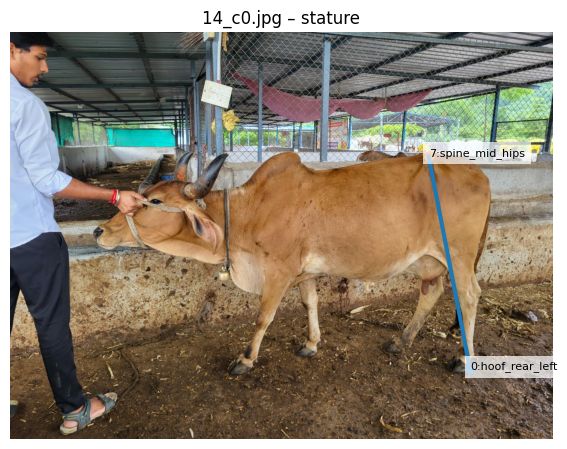

In [34]:
sample_img = random.choice(all_images)
plot_trait_on_image(sample_img, model, trait="stature", conf=0.5, figsize=(7, 7))

Sample: vetra_side_pose_dataset\images\val\89_c0.jpg


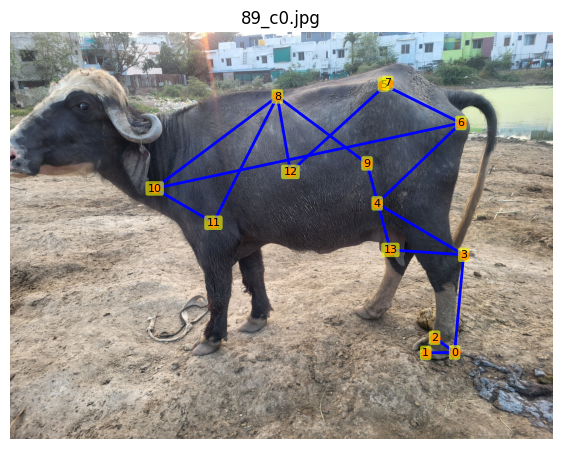

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
from pathlib import Path  # Assuming Path is imported from pathlib

# --- Use your existing defined constants ---
# KEYPOINT_NAMES and SKELETON_EDGES must be defined in your environment
# ------------------------------------------

def plot_simple_skeleton(img_path: Path, model, conf: float = 0.5, figsize=(7, 7)):
    """
    Plots the detected keypoints and skeleton edges on an image, 
    using only the keypoint index (0, 1, 2, ...) for labeling.
    """
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print("Could not read image:", img_path)
        return
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Assumes 'model' is callable and returns results in the expected format
    results = model(str(img_path), conf=conf, verbose=False)
    res = results[0]

    plt.figure(figsize=figsize)
    plt.imshow(img_rgb)
    plt.axis("off")

    if res.keypoints is None or len(res.keypoints) == 0:
        print("No keypoints detected.")
        plt.show()
        return

    kpts = res.keypoints.xy[0].cpu().numpy()  # [num_kpts, 2]

    # Draw skeleton (Line Connections)
    # Uses the SKELETON_EDGES constant from your original code
    for i, j in SKELETON_EDGES:
        x1, y1 = kpts[i]
        x2, y2 = kpts[j]
        if not (np.isnan(x1) or np.isnan(y1) or np.isnan(x2) or np.isnan(y2)):
            # Draw line: simple blue line, thickness 2
            plt.plot([x1, x2], [y1, y2], color='blue', linewidth=2, zorder=1) 

    # Draw keypoints with only the index (Simple Numbers)
    for idx, (x, y) in enumerate(kpts):
        if np.isnan(x) or np.isnan(y):
            continue
            
        # Draw the point: simple red dot, size 40
        plt.scatter(x, y, s=40, color='red', zorder=2) 
        
        # Add the index number (e.g., "0", "1", "2")
        plt.text(
            x, y, str(idx),
            color='black',            # Text color
            fontsize=8,               # Smaller font
            ha='center',              # Center text horizontally on the point
            va='center',              # Center text vertically on the point
            bbox=dict(facecolor='yellow', alpha=0.6, edgecolor='none', boxstyle='round,pad=0.2'),
            zorder=3
        )

    plt.title(img_path.name)
    plt.show()

# --- Example of how to run it ---
# You need to ensure IMAGES_DIR, model, KEYPOINT_NAMES, and SKELETON_EDGES are defined.
all_images = [p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
sample = random.choice(all_images)
print("Sample:", sample)

plot_simple_skeleton(sample, model, conf=0.5)

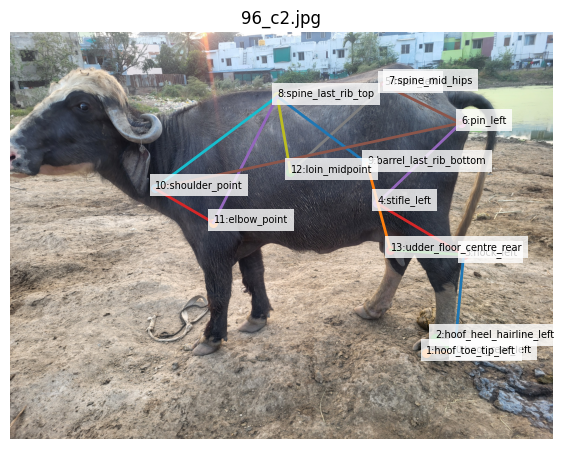

In [36]:
from pathlib import Path

# 1️⃣ Give the exact path of the image you want to visualize
image_path = Path(r"D:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_side_pose_dataset\images\val\96_c2.jpg")

# 2️⃣ Run the model and display keypoints/skeleton in the notebook
plot_pose_on_image(image_path, model, conf=0.5)


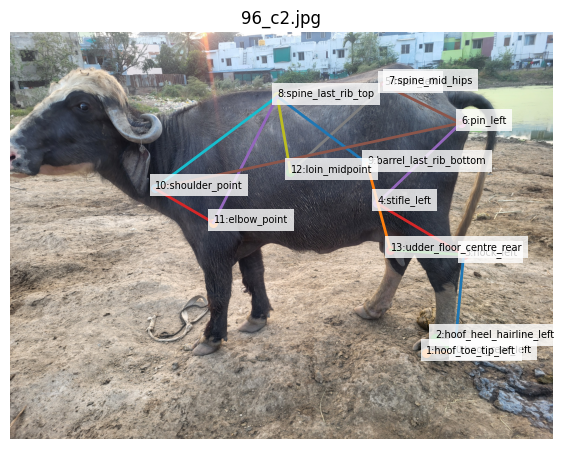

In [37]:
from pathlib import Path

# 1️⃣ Give the exact path of the image you want to visualize
image_path = Path(r"D:\Projects\VETRA\Codes\VETRA v3.0\Training and Processing\vetra_side_pose_dataset\images\val\96_c2.jpg")

# 2️⃣ Run the model and display keypoints/skeleton in the notebook
plot_pose_on_image(image_path, model, conf=0.5)


In [80]:
# ============================================
# CELL 0 – Imports & model load
# ============================================
import math
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO

# Load your 14-kp side-view pose model
# (change the path to your best.pt)
# model = YOLO(r"runs/side_view/yolo_pose_side_v1/weights/best.pt")


In [81]:
# ============================================
# CELL 1 – ArUco dictionary + marker generation
# ============================================

def _get_aruco_dict_id(dict_name: str = "DICT_4X4_50"):
    """
    Map a string name to an OpenCV ArUco dictionary constant.
    """
    name = dict_name.upper()
    ARUCO_DICT = {
        "DICT_4X4_50":           cv2.aruco.DICT_4X4_50,
        "DICT_4X4_100":          cv2.aruco.DICT_4X4_100,
        "DICT_5X5_50":           cv2.aruco.DICT_5X5_50,
        "DICT_5X5_100":          cv2.aruco.DICT_5X5_100,
        "DICT_6X6_50":           cv2.aruco.DICT_6X6_50,
        "DICT_6X6_100":          cv2.aruco.DICT_6X6_100,
        "DICT_7X7_50":           cv2.aruco.DICT_7X7_50,
        "DICT_7X7_100":          cv2.aruco.DICT_7X7_100,
        "DICT_APRILTAG_36H11":   cv2.aruco.DICT_APRILTAG_36h11,
    }
    if name not in ARUCO_DICT:
        raise ValueError(f"Unknown ArUco dictionary name: {dict_name}")
    return ARUCO_DICT[name]


def generate_aruco_marker(
    marker_id: int = 0,
    marker_size_cm: float = 10.0,
    dpi: int = 300,
    dict_name: str = "DICT_4X4_50",
    out_path: str = "aruco_10cm_id0.png",
):
    """
    Generate and save a printable ArUco marker of given physical side length.
    Print this and tape it near the cow for scaling.
    """
    dict_id = _get_aruco_dict_id(dict_name)
    aruco_dict = cv2.aruco.getPredefinedDictionary(dict_id)

    marker_size_px = int(marker_size_cm / 2.54 * dpi)  # cm -> inches -> pixels

    # Try new API first
    img = None
    if hasattr(cv2.aruco, "generateImageMarker"):
        img = cv2.aruco.generateImageMarker(aruco_dict, marker_id, marker_size_px)
    elif hasattr(cv2.aruco, "drawMarker"):
        img = np.zeros((marker_size_px, marker_size_px), dtype=np.uint8)
        cv2.aruco.drawMarker(aruco_dict, marker_id, marker_size_px, img, 1)
    else:
        raise RuntimeError(
            "Your OpenCV build does not support ArUco marker generation. "
            "Install opencv-contrib-python."
        )

    cv2.imwrite(out_path, img)
    print(f"Saved ArUco marker to {out_path} (size: {marker_size_cm} cm, id={marker_id})")

# Run once if needed:
# generate_aruco_marker(marker_id=0, marker_size_cm=10, dpi=300,
#                       dict_name="DICT_4X4_50", out_path="aruco_10cm_id0.png")


In [82]:
# ============================================
# CELL 2 – ArUco detection & cm-per-pixel scale
# ============================================

def detect_aruco_markers(img_bgr, dict_name: str = "DICT_4X4_50"):
    """
    Detect ArUco markers in a BGR image.
    Returns:
        corners: list of (4,1,2) or (4,2) arrays
        ids:     np.array of shape (N,1) or None
    """
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    dict_id = _get_aruco_dict_id(dict_name)
    aruco_dict = cv2.aruco.getPredefinedDictionary(dict_id)

    # OpenCV >= 4.7 style first, fallback to old
    try:
        params = cv2.aruco.DetectorParameters()
        detector = cv2.aruco.ArucoDetector(aruco_dict, params)
        corners, ids, _ = detector.detectMarkers(gray)
    except AttributeError:
        params = cv2.aruco.DetectorParameters_create()
        corners, ids, _ = cv2.aruco.detectMarkers(gray, aruco_dict, parameters=params)

    if ids is None or len(ids) == 0:
        return [], None
    return corners, ids


def draw_aruco_detections(img_bgr, corners, ids):
    out = img_bgr.copy()
    if ids is not None and len(corners) > 0:
        cv2.aruco.drawDetectedMarkers(out, corners, ids)
    return out


def compute_cm_per_pixel_from_aruco(corners, marker_size_cm: float):
    """
    Estimate global cm-per-pixel from one or more detected ArUco markers.
    """
    if corners is None or len(corners) == 0:
        raise RuntimeError("No ArUco corners provided to compute scale.")

    all_edge_lengths_px = []
    for m_c in corners:
        c = np.squeeze(m_c)  # (4,2)
        if c.shape != (4, 2):
            continue

        edges = [
            np.linalg.norm(c[0] - c[1]),
            np.linalg.norm(c[1] - c[2]),
            np.linalg.norm(c[2] - c[3]),
            np.linalg.norm(c[3] - c[0]),
        ]
        all_edge_lengths_px.extend(edges)

    if not all_edge_lengths_px:
        raise RuntimeError("Could not compute any valid ArUco edge lengths.")

    mean_edge_px = float(np.mean(all_edge_lengths_px))
    cm_per_pixel = marker_size_cm / mean_edge_px

    return {
        "cm_per_pixel": cm_per_pixel,
        "mean_edge_px": mean_edge_px,
        "num_markers": len(corners),
    }


In [83]:
# ============================================
# CELL 3 – ScalingEngine (Tier 1: ArUco)
# ============================================

class ScalingEngine:
    """
    Tier-1 scaling: ArUco marker.
    """

    def __init__(self, method: str, cm_per_pixel: float, meta: dict):
        self.method = method
        self.cm_per_pixel = cm_per_pixel
        self.meta = meta

    @classmethod
    def from_aruco(cls, img_bgr, marker_size_cm: float, dict_name: str = "DICT_4X4_50"):
        corners, ids = detect_aruco_markers(img_bgr, dict_name=dict_name)
        if ids is None or len(corners) == 0:
            raise RuntimeError("No ArUco markers detected in image for scaling.")

        scale_info = compute_cm_per_pixel_from_aruco(corners, marker_size_cm)
        scale_info["dict_name"] = dict_name
        scale_info["marker_size_cm"] = marker_size_cm
        scale_info["marker_ids"] = None if ids is None else ids.flatten().tolist()

        engine = cls(method="aruco", cm_per_pixel=scale_info["cm_per_pixel"], meta=scale_info)
        return engine, corners, ids


In [84]:
# ============================================
# CELL 4 – 14-kp side-view helpers & traits
# ============================================

# 14 landmarks (fixed)
# 0: hoof_rear
# 1: hoof_toe_tip
# 2: hoof_heel_hairline
# 3: hock
# 4: stifle
# 5: hook
# 6: pin
# 7: spine_last_rib_top
# 8: barrel_last_rib_bottom
# 9: withers
# 10: shoulder_point
# 11: elbow_point
# 12: front_hoof
# 13: udder_bottom

SKELETON_EDGES_14 = [
    (0, 3), (0, 1), (0, 2),
    (3, 4), (4, 6), (6, 5),
    (5, 7), (7, 9), (9, 10),
    (10, 11), (11, 12),
    (7, 8),
    (8, 13), (3, 13),
]

def _extract_kpts_from_result(res):
    """
    Extract (K,2) keypoints from a Ultralytics YOLO pose result.
    Uses the first detection (assumes single cow).
    """
    if getattr(res, "keypoints", None) is not None and len(res.keypoints) > 0:
        return res.keypoints.xy[0].cpu().numpy()
    raise ValueError("Result has no keypoints; cannot compute traits.")


def _safe_point(kpts, idx):
    if idx < 0 or idx >= kpts.shape[0]:
        return None
    x, y = kpts[idx]
    if np.isnan(x) or np.isnan(y):
        return None
    return np.array([float(x), float(y)], dtype=np.float32)


def _dist_px(kpts, i, j):
    p1 = _safe_point(kpts, i)
    p2 = _safe_point(kpts, j)
    if p1 is None or p2 is None:
        return None
    return float(np.linalg.norm(p2 - p1))


def compute_sideview_length_traits_px(kpts):
    """
    Returns a dict with all side-view length traits in pixels.

    Conventions:
      - stature: distance(5, 1)
      - heart_girth: 2 * distance(8, 11)  [always doubled, no one-side field]
      - body_length: distance(10, 6)
      - body_depth: polyline distance(8 -> 9 -> 4) [ONE side only, no doubling]
      - udder_depth: distance(4, 13)
    """
    lengths = {}

    # stature: 5 -> 1
    stature = _dist_px(kpts, 5, 1)
    if stature is not None:
        lengths["stature_px"] = stature

    # heart girth: 8 -> 11, always store doubled
    hg_one = _dist_px(kpts, 8, 11)
    if hg_one is not None:
        lengths["heart_girth_px"] = 2.0 * hg_one

    # body length: 10 -> 6
    bl = _dist_px(kpts, 10, 6)
    if bl is not None:
        lengths["body_length_px"] = bl

    # body depth: 8 -> 9 -> 4, ONE side only
    bd = _polyline_dist_px(kpts, [8, 9, 4])
    if bd is not None:
        lengths["body_depth_px"] = bd

    # udder depth: 4 -> 13
    ud = _dist_px(kpts, 4, 13)
    if ud is not None:
        lengths["udder_depth_px"] = ud

    return lengths



In [85]:
# ============================================
# CELL 5 – Measurement wrapper & px→cm conversion
# ============================================

def measure_sideview_traits_px(img_path, model, conf: float = 0.5):
    """
    Run your 14-kp side-view YOLO pose model and compute length traits in pixels.
    """
    img_path = Path(img_path)
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        raise RuntimeError(f"Could not read image at {img_path}")

    results = model(str(img_path), conf=conf, verbose=False)
    res = results[0]
    kpts_xy = _extract_kpts_from_result(res)

    traits_px = compute_sideview_length_traits_px(kpts_xy)
    return {
        "traits_px": traits_px,
        "kpts_xy": kpts_xy,
        "image_shape": img_bgr.shape[:2],  # (H, W)
    }


def convert_traits_px_to_cm(traits_px: dict, cm_per_pixel: float):
    """
    Convert {'xxx_px': value_px, ...} to {'xxx_cm': value_cm, ...}.
    """
    traits_cm = {}
    for name, val_px in traits_px.items():
        cm_name = name.replace("_px", "_cm")
        traits_cm[cm_name] = float(val_px * cm_per_pixel)
    return traits_cm


In [86]:
# ============================================
# CELL 6 – Full Tier 1 (ArUco scaling + traits)
# ============================================

def measure_image_with_aruco_scaling(
    img_path,
    model,
    marker_size_cm: float,
    dict_name: str = "DICT_4X4_50",
    conf: float = 0.5,
    show_aruco: bool = True,
):
    """
    End-to-end for one side-view image using the 14-kp model:
      1. detect ArUco marker(s) -> cm_per_pixel
      2. run pose model -> keypoints
      3. compute length traits in pixels
      4. convert to cm
      5. (optional) show marker overlay
    """
    img_path = Path(img_path)
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        raise RuntimeError(f"Could not read image at {img_path}")

    # 1) scaling engine
    scaling_engine, corners, ids = ScalingEngine.from_aruco(
        img_bgr=img_bgr,
        marker_size_cm=marker_size_cm,
        dict_name=dict_name,
    )

    print("==== ArUco scaling ====")
    print(f"Method         : {scaling_engine.method}")
    print(f"Dict           : {scaling_engine.meta['dict_name']}")
    print(f"Marker size    : {scaling_engine.meta['marker_size_cm']} cm")
    print(f"cm_per_pixel   : {scaling_engine.cm_per_pixel:.6f} cm/px")
    print(f"mean_edge_px   : {scaling_engine.meta['mean_edge_px']:.2f} px")
    print(f"# markers used : {scaling_engine.meta['num_markers']}")
    print(f"marker_ids     : {scaling_engine.meta['marker_ids']}")

    if show_aruco:
        vis = draw_aruco_detections(img_bgr, corners, ids)
        vis_rgb = cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(6, 6))
        plt.imshow(vis_rgb)
        plt.axis("off")
        plt.title(f"Aruco detection: {img_path.name}")
        plt.show()

    # 2) side-view traits in pixels
    meas = measure_sideview_traits_px(img_path, model=model, conf=conf)
    traits_px = meas["traits_px"]
    kpts_xy = meas["kpts_xy"]
    H, W = meas["image_shape"]

    if not traits_px:
        print("No traits computed; check keypoints / detections.")
        return None

    # 3) convert to cm
    traits_cm = convert_traits_px_to_cm(traits_px, scaling_engine.cm_per_pixel)

    print("\n==== Length traits (px → cm) ====")
    for name_px, val_px in traits_px.items():
        name_cm = name_px.replace("_px", "_cm")
        val_cm = traits_cm[name_cm]
        print(f"{name_px:25s}: {val_px:8.2f} px   -> {name_cm:25s}: {val_cm:8.2f} cm")

    return {
        "traits_px": traits_px,
        "traits_cm": traits_cm,
        "kpts_xy": kpts_xy,
        "image_shape": (H, W),
        "scaling_engine": scaling_engine,
    }


==== ArUco scaling ====
Method         : aruco
Dict           : DICT_4X4_50
Marker size    : 7.0 cm
cm_per_pixel   : 0.388944 cm/px
mean_edge_px   : 18.00 px
# markers used : 1
marker_ids     : [37]


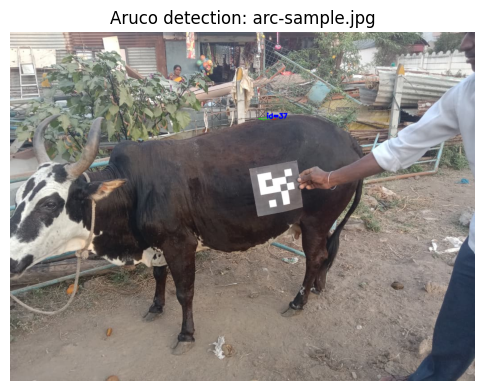


==== Length traits (px → cm) ====
stature_px               :   417.57 px   -> stature_cm               :   162.41 cm
heart_girth_px           :   448.82 px   -> heart_girth_cm           :   174.57 cm
body_length_px           :   491.33 px   -> body_length_cm           :   191.10 cm
body_depth_px            :   228.92 px   -> body_depth_cm            :    89.04 cm
udder_depth_px           :    65.22 px   -> udder_depth_cm           :    25.37 cm


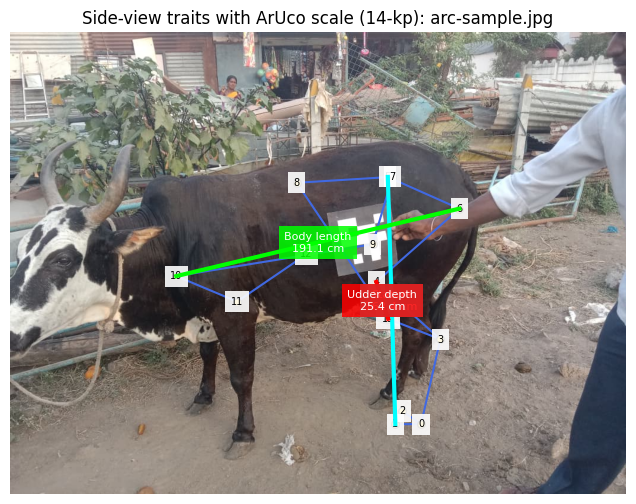

In [87]:
# ============================================
# CELL 8 – Example run
# ============================================

MARKER_SIZE_CM = 7.0  # physical side length of your printed ArUco
sample_img = r"arc-sample.jpg"

result = measure_image_with_aruco_scaling(
    img_path=sample_img,
    model=model,          # <-- your 14-kp side YOLO pose model
    marker_size_cm=MARKER_SIZE_CM,
    dict_name="DICT_4X4_50",
    conf=0.5,
    show_aruco=True,
)

if result is not None:
    plot_sideview_with_traits_cm(sample_img, result, figsize=(10, 6))


In [93]:
import cv2
import numpy as np
from pathlib import Path

# -------------------------------------------------------------
# ArUco helpers (version-safe for OpenCV 4.x new + legacy API)
# -------------------------------------------------------------

def _get_aruco_dict(dict_name: str = "DICT_4X4_50"):
    """
    Map a string name to an OpenCV ArUco dictionary constant.
    Change dict_name if you use a different marker family.
    """
    name = dict_name.upper()
    ARUCO_DICT = {
        "DICT_4X4_50":   cv2.aruco.DICT_4X4_50,
        "DICT_4X4_100":  cv2.aruco.DICT_4X4_100,
        "DICT_5X5_50":   cv2.aruco.DICT_5X5_50,
        "DICT_5X5_100":  cv2.aruco.DICT_5X5_100,
        "DICT_6X6_50":   cv2.aruco.DICT_6X6_50,
        "DICT_6X6_100":  cv2.aruco.DICT_6X6_100,
        "DICT_7X7_50":   cv2.aruco.DICT_7X7_50,
        "DICT_7X7_100":  cv2.aruco.DICT_7X7_100,
        "DICT_APRILTAG_36h11": cv2.aruco.DICT_APRILTAG_36h11,
    }
    if name not in ARUCO_DICT:
        raise ValueError(f"Unknown ArUco dictionary name: {dict_name}")
    return ARUCO_DICT[name]


def detect_aruco_markers(
    img_bgr,
    dict_name: str = "DICT_4X4_50"
):
    """
    Detect ArUco markers in a BGR image.
    Returns:
        corners: list of (4,1,2) or (4,2) arrays
        ids:     np.array of shape (N,1) or None
    """
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    dict_id = _get_aruco_dict(dict_name)

    # Get dictionary
    aruco_dict = cv2.aruco.getPredefinedDictionary(dict_id)

    # Try new API (OpenCV >= 4.7) first, fallback to legacy
    corners, ids = None, None
    try:
        # New style
        parameters = cv2.aruco.DetectorParameters()
        detector = cv2.aruco.ArucoDetector(aruco_dict, parameters)
        corners, ids, _ = detector.detectMarkers(gray)
    except AttributeError:
        # Old style
        parameters = cv2.aruco.DetectorParameters_create()
        corners, ids, _ = cv2.aruco.detectMarkers(gray, aruco_dict, parameters=parameters)

    if ids is None or len(ids) == 0:
        return [], None

    return corners, ids


def draw_aruco_detections(img_bgr, corners, ids):
    """
    Draw detected ArUco markers for visualization.
    """
    out = img_bgr.copy()
    if ids is not None and len(corners) > 0:
        cv2.aruco.drawDetectedMarkers(out, corners, ids)
    return out


def compute_cm_per_pixel_from_aruco(
    corners,
    marker_size_cm: float
):
    """
    Estimate a global cm-per-pixel scale from one or more detected ArUco markers.

    corners: list of marker corners, each shape (4,1,2) or (4,2)
    marker_size_cm: physical side length of the square marker.
    """
    if corners is None or len(corners) == 0:
        raise RuntimeError("No ArUco corners provided to compute scale.")

    all_edge_lengths_px = []

    for m_c in corners:
        c = np.squeeze(m_c)  # -> (4,2)
        if c.shape != (4, 2):
            continue

        # Four edges (0-1, 1-2, 2-3, 3-0)
        edges = [
            np.linalg.norm(c[0] - c[1]),
            np.linalg.norm(c[1] - c[2]),
            np.linalg.norm(c[2] - c[3]),
            np.linalg.norm(c[3] - c[0]),
        ]
        all_edge_lengths_px.extend(edges)

    if not all_edge_lengths_px:
        raise RuntimeError("Could not compute any valid ArUco edge lengths.")

    mean_edge_px = float(np.mean(all_edge_lengths_px))
    cm_per_pixel = marker_size_cm / mean_edge_px

    return {
        "cm_per_pixel": cm_per_pixel,
        "mean_edge_px": mean_edge_px,
        "num_markers": len(corners),
    }


class ScalingEngine:
    """
    Simple scaling engine that currently supports:
      - ArUco based scaling (Tier 1)

    Later we can add:
      - Known reference object
      - Manual two-point reference
    """

    def __init__(self, method: str, cm_per_pixel: float, meta: dict):
        self.method = method
        self.cm_per_pixel = cm_per_pixel
        self.meta = meta

    @classmethod
    def from_aruco(
        cls,
        img_bgr,
        marker_size_cm: float,
        dict_name: str = "DICT_4X4_50"
    ):
        corners, ids = detect_aruco_markers(img_bgr, dict_name=dict_name)
        if ids is None or len(corners) == 0:
            raise RuntimeError("No ArUco markers detected in image for scaling.")

        scale_info = compute_cm_per_pixel_from_aruco(
            corners=corners,
            marker_size_cm=marker_size_cm
        )
        scale_info["dict_name"] = dict_name
        scale_info["marker_size_cm"] = marker_size_cm
        scale_info["marker_ids"] = None if ids is None else ids.flatten().tolist()

        return cls(method="aruco", cm_per_pixel=scale_info["cm_per_pixel"], meta=scale_info), corners, ids


In [94]:
def convert_traits_px_to_cm_with_scale(
    traits_px: dict,
    cm_per_pixel: float
):
    """
    Convert the output of compute_trait_lengths_pixels(...) from pixels to cm
    using a global cm_per_pixel scaling.

    traits_px format (from previous code):
      trait_name -> {
          "total_length_px": float,
          "total_length_px_one_side": float,
          "segment_lengths_px": [...],
          "segments": [(i, j), ...],
          "multiplier": float,
      }
    """
    traits_cm = {}

    for trait, info in traits_px.items():
        total_cm = info["total_length_px"] * cm_per_pixel
        seg_cm = [v * cm_per_pixel for v in info["segment_lengths_px"]]

        traits_cm[trait] = {
            "total_length_cm": float(total_cm),
            "total_length_cm_one_side": float(info["total_length_px_one_side"] * cm_per_pixel),
            "segment_lengths_cm": [float(v) for v in seg_cm],
            "segments": info["segments"],
            "multiplier": info.get("multiplier", 1.0),
            "cm_per_pixel": float(cm_per_pixel),
        }

    return traits_cm


In [95]:
def measure_image_with_aruco_scaling(
    img_path,
    model,
    marker_size_cm: float,
    dict_name: str = "DICT_4X_50",
    conf: float = 0.5,
    show_aruco: bool = True,
):
    """
    End-to-end for one image:
      - detect ArUco markers
      - compute cm/pixel
      - run pose model and get trait pixel measurements
      - convert to cm

    Works for both side-view and back-view pipelines, as long as
    measure_traits_on_image(...) uses the right TRAIT_EDGES_IDX.
    """
    img_path = Path(img_path)
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        raise RuntimeError(f"Could not read image at {img_path}")

    # ---- 1) Build scaling engine from ArUco ----
    scaling_engine, corners, ids = ScalingEngine.from_aruco(
        img_bgr=img_bgr,
        marker_size_cm=marker_size_cm,
        dict_name=dict_name
    )

    print(f"Scaling method   : {scaling_engine.method}")
    print(f"cm_per_pixel     : {scaling_engine.cm_per_pixel:.6f} cm/px")
    print(f"mean_marker_edge : {scaling_engine.meta['mean_edge_px']:.2f} px")
    print(f"num_markers_used : {scaling_engine.meta['num_markers']}")
    print(f"marker_ids       : {scaling_engine.meta['marker_ids']}")

    if show_aruco:
        vis = draw_aruco_detections(img_bgr, corners, ids)
        vis_rgb = cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(6, 6))
        plt.imshow(vis_rgb)
        plt.axis("off")
        plt.title(f"Aruco detection: {img_path.name}")
        plt.show()

    # ---- 2) Trait measurement in pixels (your existing function) ----
    meas = measure_traits_on_image(img_path, model=model, conf=conf)
    traits_px = meas["traits_px"]

    if not traits_px:
        print("\nNo trait pixel measurements could be computed.")
        return None, None, scaling_engine

    # ---- 3) Convert to cm using cm_per_pixel from ArUco ----
    traits_cm = convert_traits_px_to_cm_with_scale(
        traits_px=traits_px,
        cm_per_pixel=scaling_engine.cm_per_pixel
    )

    # ---- 4) Print a summary ----
    print("\n=== Trait measurements (pixel + cm from ArUco) ===")
    for trait, info_px in traits_px.items():
        info_cm = traits_cm[trait]
        print(f"\nTrait: {trait}")
        print(f"  total_length_px          : {info_px['total_length_px']:.2f}")
        print(f"  total_length_px_one_side : {info_px['total_length_px_one_side']:.2f}")
        print(f"  total_length_cm          : {info_cm['total_length_cm']:.2f} cm")
        print(f"  total_length_cm_one_side : {info_cm['total_length_cm_one_side']:.2f} cm")
        if info_px.get("multiplier", 1.0) != 1.0:
            print(f"  multiplier               : x{info_px['multiplier']}")
        print(f"  cm_per_pixel             : {info_cm['cm_per_pixel']:.6f} cm/px")

    return traits_px, traits_cm, scaling_engine


In [100]:
import math
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# -------------------------------------------------------------------
# 0) You must already have these defined somewhere:
#    - TRAIT_EDGES_IDX   (dict: trait -> [(i, j), ...])
#    - SKELETON_EDGES    (list of (i, j))  [only needed if you plot]
#    - model             (your side-view YOLO pose model)
# -------------------------------------------------------------------

# -------------------------------------------------------------------
# 1) Side-view length-only trait config (with girth & depth doubled)
# -------------------------------------------------------------------

SIDE_VIEW_LENGTH_TRAITS = {
    "stature": {
        "multiplier": 1.0,  # withers to hoof
    },
    "heart_girth": {
        "multiplier": 2.0,  # ⬅️ double for both sides
    },
    "body_length": {
        "multiplier": 1.0,  # shoulder to pin
    },
    "body_depth": {
        "multiplier": 2.0,  # ⬅️ double for both sides
    },
    "udder_depth": {
        "multiplier": 1.0,
    },
}
# Angularity, rump_angle, rear_legs_set, foot_angle, body_condition_score
# are angle/score traits -> NOT handled here.


# -------------------------------------------------------------------
# 2) Helper to extract best keypoints from YOLO result
# -------------------------------------------------------------------

def _extract_kpts_from_result(res):
    """
    Take a single Ultralytics result object and return keypoints for
    the best detection as a (K, 2) numpy array in (x, y) pixel coords.
    """
    if not hasattr(res, "keypoints") or res.keypoints is None:
        raise RuntimeError("No keypoints found in YOLO result.")

    k_xy = res.keypoints.xy  # (num_dets, num_kpts, 2)
    if k_xy is None or len(k_xy) == 0:
        raise RuntimeError("No detections with keypoints in this image.")

    # Choose detection with highest mean keypoint confidence if available
    try:
        k_conf = res.keypoints.conf  # (num_dets, num_kpts)
        best_idx = int(k_conf.mean(dim=1).argmax())
    except Exception:
        best_idx = 0

    kpts_xy = k_xy[best_idx].cpu().numpy()  # (K, 2)
    return kpts_xy


# -------------------------------------------------------------------
# 3) Pixel-only trait measurements (length traits + doubling rules)
# -------------------------------------------------------------------

def compute_trait_lengths_pixels(
    kpts_xy: np.ndarray,
    trait_edges_idx: dict,
    side_view_length_traits: dict = SIDE_VIEW_LENGTH_TRAITS,
):
    """
    Compute pixel-based linear measurements ONLY for straight length traits.

    - Skips angle-based and score-based traits.
    - Doubles heart_girth and body_depth via 'multiplier' in config.

    Returns:
        trait_measurements_px: dict
          {
            trait_name: {
                "total_length_px": float,          # AFTER multiplier
                "total_length_px_one_side": float, # BEFORE multiplier
                "segment_lengths_px": [float, ...],
                "segments": [(i, j), ...],         # keypoint indices
                "multiplier": float,
            },
            ...
          }
    """
    trait_measurements_px = {}

    for trait, edges in trait_edges_idx.items():
        if trait not in side_view_length_traits:
            continue

        segment_lengths = []
        valid_segments = []

        for (i, j) in edges:
            x1, y1 = kpts_xy[i]
            x2, y2 = kpts_xy[j]

            if np.any(np.isnan([x1, y1, x2, y2])):
                continue

            length_px = math.dist((float(x1), float(y1)),
                                  (float(x2), float(y2)))
            segment_lengths.append(length_px)
            valid_segments.append((i, j))

        if not segment_lengths:
            continue

        one_side_total = float(sum(segment_lengths))
        mult = float(side_view_length_traits[trait]["multiplier"])
        total_with_mult = one_side_total * mult

        trait_measurements_px[trait] = {
            "total_length_px": total_with_mult,
            "total_length_px_one_side": one_side_total,
            "segment_lengths_px": [float(v) for v in segment_lengths],
            "segments": valid_segments,
            "multiplier": mult,
        }

    return trait_measurements_px


# -------------------------------------------------------------------
# 4) Side-view helper: run model + get trait pixel measurements
# -------------------------------------------------------------------

def measure_traits_on_image(
    img_path: Path,
    model,
    conf: float = 0.5,
):
    """
    1. Runs the YOLO side-view pose model on an image.
    2. Extracts best keypoints.
    3. Computes trait-wise pixel measurements (length traits only).
    """
    img_path = Path(img_path)
    results = model(str(img_path), conf=conf, verbose=False)
    res = results[0]

    kpts_xy = _extract_kpts_from_result(res)
    trait_measurements_px = compute_trait_lengths_pixels(
        kpts_xy=kpts_xy,
        trait_edges_idx=TRAIT_EDGES_IDX,
        side_view_length_traits=SIDE_VIEW_LENGTH_TRAITS,
    )

    return {
        "image_path": str(img_path),
        "keypoints_xy": kpts_xy,
        "traits_px": trait_measurements_px,
    }


# -------------------------------------------------------------------
# 5) ArUco detection + cm-per-pixel from known marker size
# -------------------------------------------------------------------

def _get_aruco_dict(dict_name: str = "DICT_4X4_50"):
    """
    Map a string name to an OpenCV ArUco dictionary constant.
    """
    name = dict_name.upper()
    ARUCO_DICT = {
        "DICT_4X4_50":   cv2.aruco.DICT_4X4_50,
        "DICT_4X4_100":  cv2.aruco.DICT_4X4_100,
        "DICT_5X5_50":   cv2.aruco.DICT_5X5_50,
        "DICT_5X5_100":  cv2.aruco.DICT_5X5_100,
        "DICT_6X6_50":   cv2.aruco.DICT_6X6_50,
        "DICT_6X6_100":  cv2.aruco.DICT_6X6_100,
        "DICT_7X7_50":   cv2.aruco.DICT_7X7_50,
        "DICT_7X7_100":  cv2.aruco.DICT_7X7_100,
        "DICT_APRILTAG_36H11": cv2.aruco.DICT_APRILTAG_36h11,
    }
    if name not in ARUCO_DICT:
        raise ValueError(f"Unknown ArUco dictionary name: {dict_name}")
    return ARUCO_DICT[name]


def detect_aruco_markers(
    img_bgr,
    dict_name: str = "DICT_4X4_50"
):
    """
    Detect ArUco markers in a BGR image.
    Returns:
        corners: list of (4,1,2) or (4,2) arrays
        ids:     np.array of shape (N,1) or None
    """
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    dict_id = _get_aruco_dict(dict_name)

    aruco_dict = cv2.aruco.getPredefinedDictionary(dict_id)

    # Try new API (OpenCV >= 4.7) first, fallback to legacy
    corners, ids = None, None
    try:
        parameters = cv2.aruco.DetectorParameters()
        detector = cv2.aruco.ArucoDetector(aruco_dict, parameters)
        corners, ids, _ = detector.detectMarkers(gray)
    except AttributeError:
        parameters = cv2.aruco.DetectorParameters_create()
        corners, ids, _ = cv2.aruco.detectMarkers(gray, aruco_dict, parameters=parameters)

    if ids is None or len(ids) == 0:
        return [], None

    return corners, ids


def draw_aruco_detections(img_bgr, corners, ids):
    """
    Draw detected ArUco markers for visualization.
    """
    out = img_bgr.copy()
    if ids is not None and len(corners) > 0:
        cv2.aruco.drawDetectedMarkers(out, corners, ids)
    return out


def compute_cm_per_pixel_from_aruco(
    corners,
    marker_size_cm: float
):
    """
    Estimate a global cm-per-pixel scale from one or more detected ArUco markers.
    marker_size_cm: physical side length of the square marker.
    """
    if corners is None or len(corners) == 0:
        raise RuntimeError("No ArUco corners provided to compute scale.")

    all_edge_lengths_px = []

    for m_c in corners:
        c = np.squeeze(m_c)  # -> (4,2)
        if c.shape != (4, 2):
            continue

        edges = [
            np.linalg.norm(c[0] - c[1]),
            np.linalg.norm(c[1] - c[2]),
            np.linalg.norm(c[2] - c[3]),
            np.linalg.norm(c[3] - c[0]),
        ]
        all_edge_lengths_px.extend(edges)

    if not all_edge_lengths_px:
        raise RuntimeError("Could not compute any valid ArUco edge lengths.")

    mean_edge_px = float(np.mean(all_edge_lengths_px))
    cm_per_pixel = marker_size_cm / mean_edge_px

    return {
        "cm_per_pixel": cm_per_pixel,
        "mean_edge_px": mean_edge_px,
        "num_markers": len(corners),
    }


class ScalingEngine:
    """
    Tier-1 scaling engine: ArUco-based cm-per-pixel.
    """

    def __init__(self, method: str, cm_per_pixel: float, meta: dict):
        self.method = method
        self.cm_per_pixel = cm_per_pixel
        self.meta = meta

    @classmethod
    def from_aruco(
        cls,
        img_bgr,
        marker_size_cm: float,
        dict_name: str = "DICT_4X4_50"
    ):
        corners, ids = detect_aruco_markers(img_bgr, dict_name=dict_name)
        if ids is None or len(corners) == 0:
            raise RuntimeError("No ArUco markers detected in image for scaling.")

        scale_info = compute_cm_per_pixel_from_aruco(
            corners=corners,
            marker_size_cm=marker_size_cm
        )
        scale_info["dict_name"] = dict_name
        scale_info["marker_size_cm"] = marker_size_cm
        scale_info["marker_ids"] = None if ids is None else ids.flatten().tolist()

        return cls(
            method="aruco",
            cm_per_pixel=scale_info["cm_per_pixel"],
            meta=scale_info
        ), corners, ids


# -------------------------------------------------------------------
# 6) Convert trait pixels -> cm using a global scale
# -------------------------------------------------------------------

def convert_traits_px_to_cm_with_scale(
    traits_px: dict,
    cm_per_pixel: float
):
    """
    Convert the output of compute_trait_lengths_pixels(...) from pixels to cm
    using a global cm_per_pixel scaling.
    """
    traits_cm = {}

    for trait, info in traits_px.items():
        total_cm = info["total_length_px"] * cm_per_pixel
        seg_cm = [v * cm_per_pixel for v in info["segment_lengths_px"]]

        traits_cm[trait] = {
            "total_length_cm": float(total_cm),
            "total_length_cm_one_side": float(info["total_length_px_one_side"] * cm_per_pixel),
            "segment_lengths_cm": [float(v) for v in seg_cm],
            "segments": info["segments"],
            "multiplier": info.get("multiplier", 1.0),
            "cm_per_pixel": float(cm_per_pixel),
        }

    return traits_cm


# -------------------------------------------------------------------
# 7) End-to-end: ArUco scaling + trait measurement on one image
# -------------------------------------------------------------------

def measure_image_with_aruco_scaling(
    img_path,
    model,
    marker_size_cm: float,
    dict_name: str = "DICT_4X4_50",
    conf: float = 0.5,
    show_aruco: bool = True,
):
    """
    1) Detect ArUco marker -> cm_per_pixel.
    2) Run side-view pose model -> trait pixel measurements.
    3) Convert pixel lengths -> cm.

    Works for current side-view pipeline.
    """
    img_path = Path(img_path)
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        raise RuntimeError(f"Could not read image at {img_path}")

    # ---- 1) Scaling from ArUco ----
    scaling_engine, corners, ids = ScalingEngine.from_aruco(
        img_bgr=img_bgr,
        marker_size_cm=marker_size_cm,
        dict_name=dict_name
    )

    print(f"Scaling method   : {scaling_engine.method}")
    print(f"cm_per_pixel     : {scaling_engine.cm_per_pixel:.6f} cm/px")
    print(f"mean_marker_edge : {scaling_engine.meta['mean_edge_px']:.2f} px")
    print(f"num_markers_used : {scaling_engine.meta['num_markers']}")
    print(f"marker_ids       : {scaling_engine.meta['marker_ids']}")

    if show_aruco:
        vis = draw_aruco_detections(img_bgr, corners, ids)
        vis_rgb = cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(6, 6))
        plt.imshow(vis_rgb)
        plt.axis("off")
        plt.title(f"Aruco detection: {img_path.name}")
        plt.show()

    # ---- 2) Trait measurement in pixels ----
    meas = measure_traits_on_image(img_path, model=model, conf=conf)
    traits_px = meas["traits_px"]

    if not traits_px:
        print("\nNo trait pixel measurements could be computed.")
        return None, None, scaling_engine

    # ---- 3) Convert to cm ----
    traits_cm = convert_traits_px_to_cm_with_scale(
        traits_px=traits_px,
        cm_per_pixel=scaling_engine.cm_per_pixel
    )

    # ---- 4) Print summary ----
    print("\n=== Trait measurements (pixel + cm from ArUco) ===")
    for trait, info_px in traits_px.items():
        info_cm = traits_cm[trait]
        print(f"\nTrait: {trait}")
        print(f"  total_length_px          : {info_px['total_length_px']:.2f}")
        print(f"  total_length_px_one_side : {info_px['total_length_px_one_side']:.2f}")
        print(f"  total_length_cm          : {info_cm['total_length_cm']:.2f} cm")
        print(f"  total_length_cm_one_side : {info_cm['total_length_cm_one_side']:.2f} cm")
        if info_px.get("multiplier", 1.0) != 1.0:
            print(f"  multiplier               : x{info_px['multiplier']}")
        print(f"  cm_per_pixel             : {info_cm['cm_per_pixel']:.6f} cm/px")

    return traits_px, traits_cm, scaling_engine


Scaling method   : aruco
cm_per_pixel     : 0.277817 cm/px
mean_marker_edge : 18.00 px
num_markers_used : 1
marker_ids       : [37]


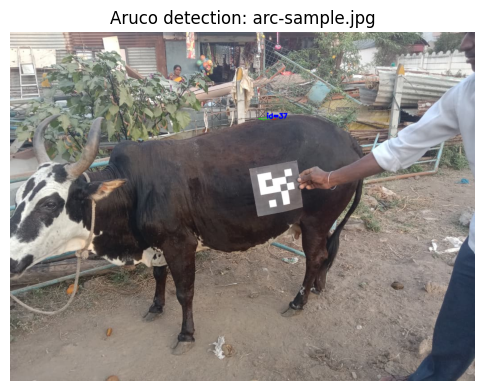


=== Trait measurements (pixel + cm from ArUco) ===

Trait: stature
  total_length_px          : 420.31
  total_length_px_one_side : 420.31
  total_length_cm          : 116.77 cm
  total_length_cm_one_side : 116.77 cm
  cm_per_pixel             : 0.277817 cm/px

Trait: heart_girth
  total_length_px          : 448.82
  total_length_px_one_side : 224.41
  total_length_cm          : 124.69 cm
  total_length_cm_one_side : 62.35 cm
  multiplier               : x2.0
  cm_per_pixel             : 0.277817 cm/px

Trait: body_length
  total_length_px          : 491.34
  total_length_px_one_side : 491.34
  total_length_cm          : 136.50 cm
  total_length_cm_one_side : 136.50 cm
  cm_per_pixel             : 0.277817 cm/px

Trait: body_depth
  total_length_px          : 329.87
  total_length_px_one_side : 164.94
  total_length_cm          : 91.64 cm
  total_length_cm_one_side : 45.82 cm
  multiplier               : x2.0
  cm_per_pixel             : 0.277817 cm/px

Trait: udder_depth
  total_leng

In [104]:
MARKER_SIZE_CM = 5.0  # your ArUco physical side size in cm
img_path_side = "arc-sample.jpg"  # your image with both cow + marker

traits_px_side, traits_cm_side, scale_side = measure_image_with_aruco_scaling(
    img_path=img_path_side,
    model=model,           # side-view YOLO pose model
    marker_size_cm=MARKER_SIZE_CM,
    dict_name="DICT_4X4_50",
    conf=0.5,
    show_aruco=True,
)


In [110]:
import math
import numpy as np
import cv2
from pathlib import Path

# ----------------------------------------------------------
# 1) Basic helpers
# ----------------------------------------------------------

def _safe_point(kpts, idx):
    """
    Safely get keypoint idx as a 2D point.
    Returns None if idx is out of range or NaN.
    """
    if idx < 0 or idx >= len(kpts):
        return None
    x, y = kpts[idx]
    if np.isnan(x) or np.isnan(y):
        return None
    return np.array([float(x), float(y)], dtype=np.float32)



def _dist_px(kpts, i, j):
    """Euclidean distance between keypoints i and j in pixels."""
    p1 = _safe_point(kpts, i)
    p2 = _safe_point(kpts, j)
    if p1 is None or p2 is None:
        return None
    return float(np.linalg.norm(p2 - p1))


def _polyline_dist_px(kpts, idx_list):
    """Sum of distances along a polyline (i0->i1->i2...)."""
    d = 0.0
    for a, b in zip(idx_list, idx_list[1:]):
        seg = _dist_px(kpts, a, b)
        if seg is None:
            return None
        d += seg
    return float(d)


def _angle_between_vectors_deg(v1, v2):
    """Return angle between two 2D vectors in degrees (0..180)."""
    v1 = np.asarray(v1, dtype=np.float32)
    v2 = np.asarray(v2, dtype=np.float32)
    n1 = np.linalg.norm(v1)
    n2 = np.linalg.norm(v2)
    if n1 == 0 or n2 == 0:
        return None
    cosang = float(np.dot(v1, v2) / (n1 * n2))
    cosang = max(min(cosang, 1.0), -1.0)
    return float(np.degrees(np.arccos(cosang)))


def _angle_at_point_deg(kpts, a_idx, b_idx, c_idx):
    """
    Angle ABC (at point B) in degrees.
    """
    pb = _safe_point(kpts, b_idx)
    pa = _safe_point(kpts, a_idx)
    pc = _safe_point(kpts, c_idx)
    if pa is None or pb is None or pc is None:
        return None
    v1 = pa - pb
    v2 = pc - pb
    return _angle_between_vectors_deg(v1, v2)


# ----------------------------------------------------------
# 2) Length traits in pixels (your new definitions)
# ----------------------------------------------------------

def compute_sideview_length_traits_px(kpts):
    """
    Returns a dict with all side-view length traits in pixels.
    Applies *2 for heart_girth and body_depth as requested.
    """
    lengths = {}

    # stature: 5 -> 1
    stature = _dist_px(kpts, 5, 1)
    if stature is not None:
        lengths["stature_px"] = stature

    # heart girth: 8 -> 11, then *2
    hg_one = _dist_px(kpts, 8, 11)
    if hg_one is not None:
        lengths["heart_girth_one_side_px"] = hg_one
        lengths["heart_girth_px"] = 2.0 * hg_one

    # body length: 10 -> 6
    bl = _dist_px(kpts, 10, 6)
    if bl is not None:
        lengths["body_length_px"] = bl

    # body depth: 8 -> 9 -> 4, then *2
    bd_one = _polyline_dist_px(kpts, [8, 9, 4])
    if bd_one is not None:
        lengths["body_depth_one_side_px"] = bd_one
        lengths["body_depth_px"] = 2.0 * bd_one

    # udder depth: 4 -> 13
    ud = _dist_px(kpts, 4, 13)
    if ud is not None:
        lengths["udder_depth_px"] = ud

    return lengths


# ----------------------------------------------------------
# 3) Angle-based traits -> ATC scores (1,5,9)
# ----------------------------------------------------------

def score_rump_angle(kpts, img_height, tol_frac=0.02):
    """
    Uses vertical positions of points 7 (hip) and 6 (pin).
    y increases downward in images.
    """
    p7 = _safe_point(kpts, 7)
    p6 = _safe_point(kpts, 6)
    if p7 is None or p6 is None:
        return None

    y7, y6 = p7[1], p6[1]
    dy = y6 - y7  # >0 => point 6 lower than 7
    tol = tol_frac * img_height

    if dy < -tol:
        score, label = 1, "High"
    elif dy > tol:
        score, label = 9, "Low"
    else:
        score, label = 5, "Intermediate"

    return {
        "trait": "rump_angle",
        "dy_px": float(dy),
        "tol_px": float(tol),
        "score": score,
        "label": label,
    }


def score_rear_legs_set(kpts,
                        straight_thresh_deg=8.0,
                        curved_thresh_deg=18.0):
    """
    Uses line from 0 -> 6.
    Measures deviation from vertical (0 deg = perfectly vertical).
    """
    p0 = _safe_point(kpts, 0)
    p6 = _safe_point(kpts, 6)
    if p0 is None or p6 is None:
        return None

    v = p6 - p0
    # angle from vertical: swap dx,dy in atan2
    angle = abs(math.degrees(math.atan2(abs(v[0]), abs(v[1]) + 1e-6)))

    if angle <= straight_thresh_deg:
        score, label = 1, "Straight"
    elif angle >= curved_thresh_deg:
        score, label = 9, "Curved"
    else:
        score, label = 5, "Intermediate"

    return {
        "trait": "rear_legs_set",
        "angle_from_vertical_deg": float(angle),
        "score": score,
        "label": label,
    }


def score_foot_angle(kpts,
                     low_thresh_deg=100.0,
                     steep_thresh_deg=140.0):
    """
    Uses points 0-1-2.
    Angle at point 1 between segments (0-1) and (2-1).
    As per your rule:
      - larger angle  -> score 1 : Low
      - very small    -> score 9 : Steep
      - middle        -> score 5 : Intermediate
    """
    ang = _angle_at_point_deg(kpts, 0, 1, 2)
    if ang is None:
        return None

    if ang >= steep_thresh_deg:
        score, label = 1, "Low"
    elif ang <= low_thresh_deg:
        score, label = 9, "Steep"
    else:
        score, label = 5, "Intermediate"

    return {
        "trait": "foot_angle",
        "joint_angle_deg": float(ang),
        "score": score,
        "label": label,
    }


def score_angularity(kpts,
                     non_ang_thresh_deg=120.0,
                     ang_thresh_deg=150.0):
    """
    Uses points 12-8-9.
    Angle at point 8.
      - small angle  -> Non-angular (1)
      - large angle  -> Angular (9)
    """
    ang = _angle_at_point_deg(kpts, 12, 8, 9)
    if ang is None:
        return None

    if ang <= non_ang_thresh_deg:
        score, label = 1, "Non-angular"
    elif ang >= ang_thresh_deg:
        score, label = 9, "Angular"
    else:
        score, label = 5, "Intermediate"

    return {
        "trait": "angularity",
        "angle_deg": float(ang),
        "score": score,
        "label": label,
    }


def score_udder_from_seg_label(label: str):
    """
    Map udder segmentation classification to ATC-like score.
    E.g. you said: strong / weak / average.
    """
    if label is None:
        return None

    label = label.lower()
    mapping = {
        "weak":   (1, "Weak"),
        "average": (5, "Average"),
        "avg":     (5, "Average"),
        "strong": (9, "Strong"),
    }
    if label not in mapping:
        return None

    score, nice = mapping[label]
    return {
        "trait": "udder_strength",
        "class": nice,
        "score": score,
    }


In [111]:
def compute_sideview_atc_for_image(
    img_path,
    model,
    conf: float = 0.5,
    cm_per_pixel: float = None,   # optional, if you still want to plug ArUco scale
    udder_label: str = None,      # output from your udder segmentation model
):
    """
    - Runs side-view pose model on img_path
    - Extracts best keypoints
    - Computes:
        * length traits in px
        * (optionally) same in cm if cm_per_pixel is given
        * angle-based traits + ATC scores (1/5/9)
        * udder segmentation-based score (1/5/9)
    """
    img_path = Path(img_path)
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        raise RuntimeError(f"Could not read image at {img_path}")
    H, W = img_bgr.shape[:2]

    # 1) Run model and get keypoints
    results = model(str(img_path), conf=conf, verbose=False)
    res = results[0]
    kpts_xy = _extract_kpts_from_result(res)  # (K, 2)

    # 2) Length traits (px, and optional cm)
    length_px = compute_sideview_length_traits_px(kpts_xy)
    length_cm = None
    if cm_per_pixel is not None:
        length_cm = {
            name.replace("_px", "_cm"): val * cm_per_pixel
            for name, val in length_px.items()
        }

    # 3) Angle/shape traits -> ATC scores
    rump_info = score_rump_angle(kpts_xy, img_height=H)
    rear_leg_info = score_rear_legs_set(kpts_xy)
    foot_info = score_foot_angle(kpts_xy)
    ang_info = score_angularity(kpts_xy)

    angle_scores = {
        k["trait"]: k
        for k in [rump_info, rear_leg_info, foot_info, ang_info]
        if k is not None
    }

    # 4) Udder segmentation-based score
    udder_info = score_udder_from_seg_label(udder_label)
    if udder_info is not None:
        angle_scores[udder_info["trait"]] = udder_info

    return {
        "image_path": str(img_path),
        "image_shape": (H, W),
        "keypoints_xy": kpts_xy,
        "lengths_px": length_px,
        "lengths_cm": length_cm,
        "angle_based_scores": angle_scores,
    }


In [112]:
img_path = "arc-sample.jpg"   # your side-view image
# If you trust your ArUco cm_per_pixel, pass it; otherwise leave as None.
cm_per_pixel = None           # or scale_side.cm_per_pixel from ArUco engine
# Suppose your udder segmentation model returns: "strong", "weak", "average"
udder_cls = "strong"          # <-- fill from your model

res = compute_sideview_atc_for_image(
    img_path=img_path,
    model=model,
    conf=0.5,
    cm_per_pixel=cm_per_pixel,
    udder_label=udder_cls,
)

print("Lengths (px):", res["lengths_px"])
if res["lengths_cm"] is not None:
    print("Lengths (cm):", res["lengths_cm"])

print("\nAngle / shape trait scores:")
for name, info in res["angle_based_scores"].items():
    print(name, "->", info)


Lengths (px): {'stature_px': 417.5743713378906, 'heart_girth_one_side_px': 224.41244506835938, 'heart_girth_px': 448.82489013671875, 'body_length_px': 491.3349914550781, 'body_depth_one_side_px': 228.92087936401367, 'body_depth_px': 457.84175872802734, 'udder_depth_px': 65.21785736083984}

Angle / shape trait scores:
rump_angle -> {'trait': 'rump_angle', 'dy_px': 53.68070983886719, 'tol_px': 15.6, 'score': 9, 'label': 'Low'}
rear_legs_set -> {'trait': 'rear_legs_set', 'angle_from_vertical_deg': 10.070563195176497, 'score': 5, 'label': 'Intermediate'}
foot_angle -> {'trait': 'foot_angle', 'joint_angle_deg': 62.2477671309568, 'score': 9, 'label': 'Steep'}
angularity -> {'trait': 'angularity', 'angle_deg': 43.11594282982376, 'score': 1, 'label': 'Non-angular'}
udder_strength -> {'trait': 'udder_strength', 'class': 'Strong', 'score': 9}


In [113]:
import matplotlib.pyplot as plt

def plot_sideview_trait_checks(
    img_path,
    model,
    conf: float = 0.5,
    figsize=(8, 8)
):
    img_path = Path(img_path)
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        raise RuntimeError(f"Could not read image at {img_path}")
    H, W = img_bgr.shape[:2]
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Run model & get keypoints
    results = model(str(img_path), conf=conf, verbose=False)
    res = results[0]
    kpts = _extract_kpts_from_result(res)

    # Compute all metrics / scores
    length_px = compute_sideview_length_traits_px(kpts)
    rump_info = score_rump_angle(kpts, img_height=H)
    rear_leg_info = score_rear_legs_set(kpts)
    foot_info = score_foot_angle(kpts)
    ang_info = score_angularity(kpts)

    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img_rgb)
    ax.axis("off")

    # ---------- draw base skeleton ----------
    for i, j in SKELETON_EDGES:
        p1 = _safe_point(kpts, i)
        p2 = _safe_point(kpts, j)
        if p1 is None or p2 is None:
            continue
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]],
                color="blue", linewidth=1.5, zorder=1)

    # Draw keypoints with index labels
    for idx, (x, y) in enumerate(kpts):
        if np.isnan(x) or np.isnan(y):
            continue
        ax.scatter(x, y, s=30, color="red", zorder=2)
        ax.text(
            x, y, str(idx),
            color="black",
            fontsize=7,
            ha="center",
            va="center",
            bbox=dict(facecolor="yellow", alpha=0.6,
                      edgecolor="none", boxstyle="round,pad=0.15"),
            zorder=3
        )

    # ---------- helper to draw labelled lines ----------
    def draw_line(i, j, color, label):
        p1 = _safe_point(kpts, i)
        p2 = _safe_point(kpts, j)
        if p1 is None or p2 is None:
            return
        ax.plot([p1[0], p2[0]], [p1[1], p2[1]],
                color=color, linewidth=3, zorder=4)
        mid = (p1 + p2) / 2.0
        ax.text(
            mid[0], mid[1], label,
            color="white",
            fontsize=9,
            ha="center",
            va="center",
            bbox=dict(facecolor=color, alpha=0.7,
                      edgecolor="none", boxstyle="round,pad=0.2"),
            zorder=5
        )

    # ---------- draw length traits ----------
    # stature: 5-1
    draw_line(5, 1, color="cyan", label="Stature")

    # heart girth: 8-11
    draw_line(8, 11, color="magenta", label="Heart girth (one side)")

    # body length: 10-6
    draw_line(10, 6, color="lime", label="Body length")

    # body depth: 8-9-4
    p8 = _safe_point(kpts, 8)
    p9 = _safe_point(kpts, 9)
    p4 = _safe_point(kpts, 4)
    if p8 is not None and p9 is not None and p4 is not None:
        ax.plot([p8[0], p9[0]], [p8[1], p9[1]],
                color="orange", linewidth=3, zorder=4)
        ax.plot([p9[0], p4[0]], [p9[1], p4[1]],
                color="orange", linewidth=3, zorder=4)
        mid_bd = (p8 + p4) / 2.0
        ax.text(
            mid_bd[0], mid_bd[1], "Body depth (one side)",
            color="white",
            fontsize=9,
            ha="center",
            va="center",
            bbox=dict(facecolor="orange", alpha=0.7,
                      edgecolor="none", boxstyle="round,pad=0.2"),
            zorder=5
        )

    # udder depth: 4-13
    draw_line(4, 13, color="red", label="Udder depth")

    # ---------- draw angle / position visualizations ----------
    # Rump angle: horizontal references at 7 and 6
    if rump_info is not None:
        p7 = _safe_point(kpts, 7)
        p6 = _safe_point(kpts, 6)
        if p7 is not None and p6 is not None:
            # horizontal lines
            ax.hlines(p7[1], p7[0] - 60, p7[0] + 60,
                      colors="yellow", linestyles="--", linewidth=2, zorder=4)
            ax.hlines(p6[1], p6[0] - 60, p6[0] + 60,
                      colors="yellow", linestyles="--", linewidth=2, zorder=4)
            ax.text(
                p6[0] + 70, (p6[1] + p7[1]) / 2,
                f"Rump: {rump_info['label']} ({rump_info['score']})",
                color="black",
                fontsize=9,
                bbox=dict(facecolor="yellow", alpha=0.8,
                          edgecolor="none", boxstyle="round,pad=0.2"),
                zorder=5
            )

    # Rear legs set: compare line 0-6 to vertical
    if rear_leg_info is not None:
        p0 = _safe_point(kpts, 0)
        p6 = _safe_point(kpts, 6)
        if p0 is not None and p6 is not None:
            # actual line
            ax.plot([p0[0], p6[0]], [p0[1], p6[1]],
                    color="white", linewidth=3, zorder=4)
            # vertical reference line at x = p0.x
            ax.vlines(p0[0], p0[1] - 100, p0[1] + 100,
                      colors="white", linestyles="--", linewidth=2, zorder=4)
            ax.text(
                p0[0] - 70, p0[1] - 110,
                f"Rear legs set: {rear_leg_info['label']} "
                f"({rear_leg_info['score']})\n"
                f"{rear_leg_info['angle_from_vertical_deg']:.1f}° from vertical",
                color="black",
                fontsize=8,
                bbox=dict(facecolor="white", alpha=0.8,
                          edgecolor="none", boxstyle="round,pad=0.2"),
                zorder=5
            )

    # Foot angle: angle at 1 (0-1-2)
    if foot_info is not None:
        p0 = _safe_point(kpts, 0)
        p1 = _safe_point(kpts, 1)
        p2 = _safe_point(kpts, 2)
        if p0 is not None and p1 is not None and p2 is not None:
            ax.plot([p0[0], p1[0]], [p0[1], p1[1]],
                    color="cyan", linewidth=3, zorder=4)
            ax.plot([p2[0], p1[0]], [p2[1], p1[1]],
                    color="cyan", linewidth=3, zorder=4)
            ax.text(
                p1[0] + 40, p1[1],
                f"Foot angle: {foot_info['label']} "
                f"({foot_info['score']})\n"
                f"{foot_info['joint_angle_deg']:.1f}°",
                color="black",
                fontsize=8,
                bbox=dict(facecolor="cyan", alpha=0.8,
                          edgecolor="none", boxstyle="round,pad=0.2"),
                zorder=5
            )

    # Angularity: angle at 8 (12-8-9)
    if ang_info is not None:
        p12 = _safe_point(kpts, 12)
        p8 = _safe_point(kpts, 8)
        p9 = _safe_point(kpts, 9)
        if p12 is not None and p8 is not None and p9 is not None:
            ax.plot([p12[0], p8[0]], [p12[1], p8[1]],
                    color="green", linewidth=3, zorder=4)
            ax.plot([p9[0], p8[0]], [p9[1], p8[1]],
                    color="green", linewidth=3, zorder=4)
            ax.text(
                p8[0] + 40, p8[1] - 40,
                f"Angularity: {ang_info['label']} "
                f"({ang_info['score']})\n"
                f"{ang_info['angle_deg']:.1f}°",
                color="black",
                fontsize=8,
                bbox=dict(facecolor="green", alpha=0.8,
                          edgecolor="none", boxstyle="round,pad=0.2"),
                zorder=5
            )

    ax.set_title(f"Side-view ATC traits: {img_path.name}")
    plt.show()


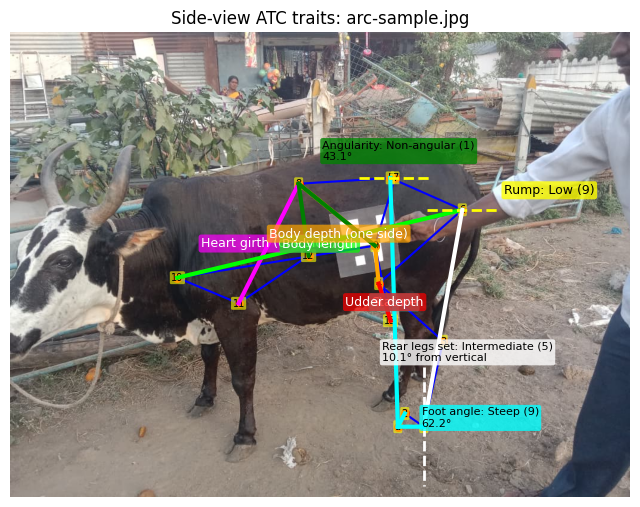

In [114]:
img_path = "arc-sample.jpg"  # or any side-view image
plot_sideview_trait_checks(img_path, model, conf=0.5, figsize=(8, 8))
